In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

%matplotlib inline

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nTarget Variable ('Churn') Distribution:")
print(df['Churn'].value_counts())

df.head()

Dataset Shape: (7043, 21)

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Target Variable ('Churn') Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("--- Dataset Info ---")
df.info()

print("\n--- Summary Statistics (Numerical Features) ---")
display(df.describe())

print("\n--- Summary Statistics (Categorical Features) ---")
display(df.describe(include='object'))

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



--- Summary Statistics (Categorical Features) ---


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


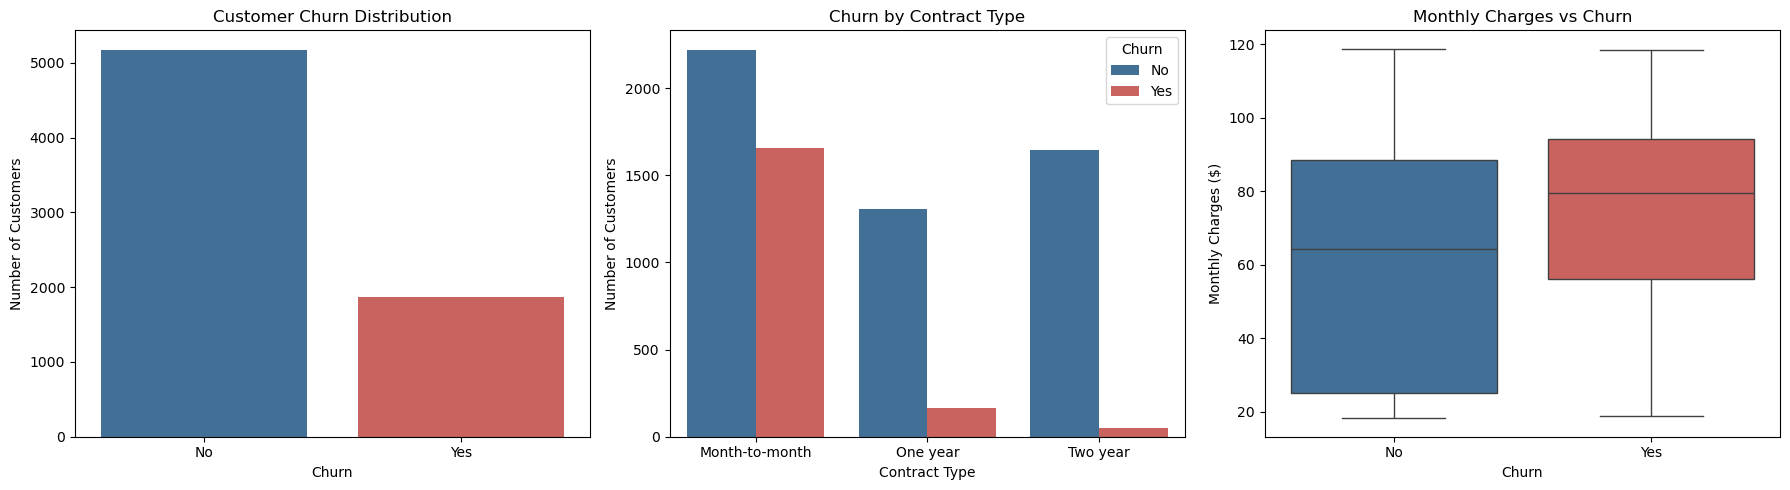

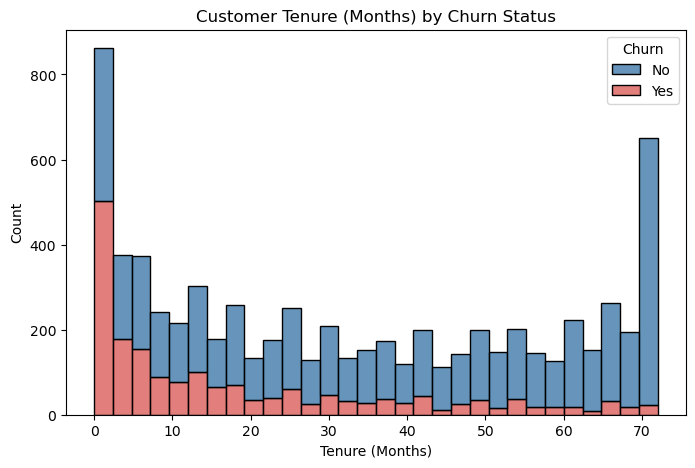

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Target Variable Distribution (Churn: Yes vs No)
sns.countplot(x='Churn', data=df, hue='Churn', palette=['#3470a3', '#d9534f'], legend=False, ax=axes[0])
axes[0].set_title('Customer Churn Distribution')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel('Number of Customers')

# Chart 2: Churn by Contract Type
sns.countplot(x='Contract', hue='Churn', data=df, palette=['#3470a3', '#d9534f'], ax=axes[1])
axes[1].set_title('Churn by Contract Type')
axes[1].set_xlabel('Contract Type')
axes[1].set_ylabel('Number of Customers')

# Chart 3: Monthly Charges Distribution by Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, hue='Churn', palette=['#3470a3', '#d9534f'], legend=False, ax=axes[2])
axes[2].set_title('Monthly Charges vs Churn')
axes[2].set_xlabel('Churn')
axes[2].set_ylabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()

# Chart 4: Tenure Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', palette=['#3470a3', '#d9534f'], bins=30)
plt.title('Customer Tenure (Months) by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')
plt.show()

In [5]:
# 1. Drop customerID (not useful for prediction)
df_clean = df.drop(columns=['customerID'])

# 2. Convert TotalCharges to numeric (coercing blank strings to NaN) and fill missing values
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
print("Missing values in TotalCharges before imputation:", df_clean['TotalCharges'].isnull().sum())
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(df_clean['TotalCharges'].median())

# 3. Encode Target Variable ('No' -> 0, 'Yes' -> 1)
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

# 4. Separate Features (X) and Target (y)
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

# 5. One-Hot Encode categorical features
X_encoded = pd.get_dummies(X, drop_first=True)
print("Shape after One-Hot Encoding:", X_encoded.shape)

# 6. 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# 7. Normalize / Standardize Features (crucial for Neural Networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

Missing values in TotalCharges before imputation: 11
Shape after One-Hot Encoding: (7043, 30)
X_train_scaled shape: (5634, 30)
X_test_scaled shape : (1409, 30)


Neural Network trained in 19 epochs.


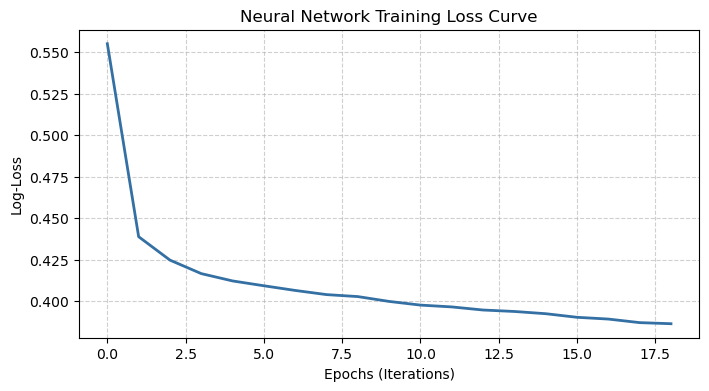

In [6]:
# Initialize Multi-Layer Perceptron (Artificial Neural Network)
# Two hidden layers: 64 neurons and 32 neurons, ReLU activation, Adam optimizer
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

# Train the Neural Network
nn_model.fit(X_train_scaled, y_train)

# Predict class labels and probabilities
y_pred = nn_model.predict(X_test_scaled)
y_pred_prob = nn_model.predict_proba(X_test_scaled)[:, 1]

print(f"Neural Network trained in {nn_model.n_iter_} epochs.")

# Plot Training Loss Curve
plt.figure(figsize=(8, 4))
plt.plot(nn_model.loss_curve_, color='#3470a3', lw=2)
plt.title('Neural Network Training Loss Curve')
plt.xlabel('Epochs (Iterations)')
plt.ylabel('Log-Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Accuracy : 0.7942 (79.42%)
Precision: 0.6321
Recall   : 0.5374
F1-Score : 0.5809
ROC-AUC  : 0.8410

--- Classification Report ---
              precision    recall  f1-score   support

No Churn (0)       0.84      0.89      0.86      1035
   Churn (1)       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



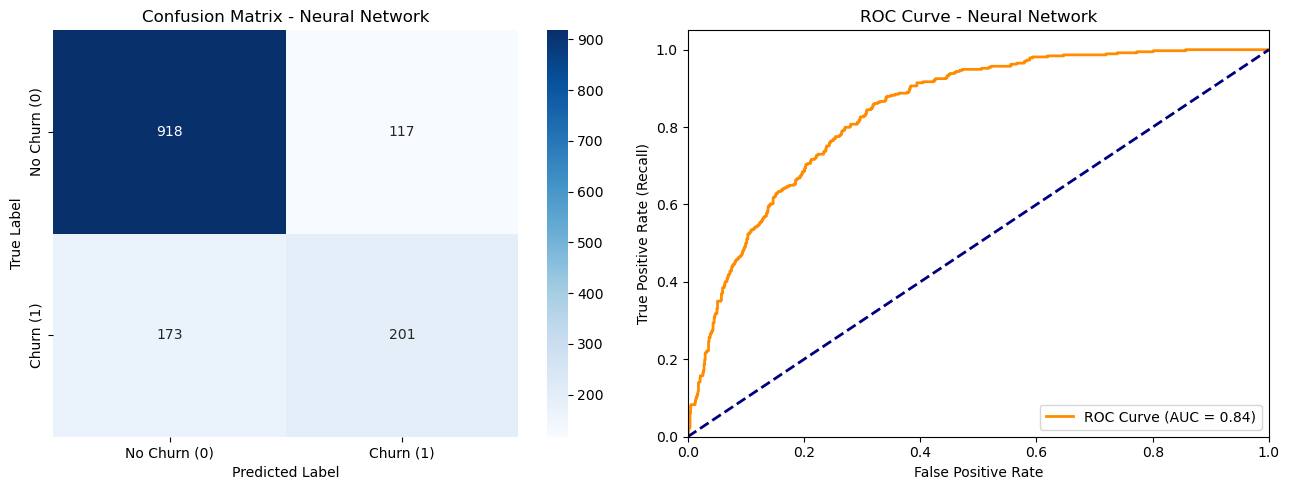

In [7]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['No Churn (0)', 'Churn (1)']))

# Plot Confusion Matrix & ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[0].set_title('Confusion Matrix - Neural Network')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('ROC Curve - Neural Network')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()